In [2]:
import pandas as pd

df = pd.read_csv("/Users/lakshmi/Desktop/python_projects/Project_3/data/emi_prediction_dataset.csv")

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 rows:")
print(df.head())

Shape: (404800, 27)

Columns:
['age', 'gender', 'marital_status', 'education', 'monthly_salary', 'employment_type', 'years_of_employment', 'company_type', 'house_type', 'monthly_rent', 'family_size', 'dependents', 'school_fees', 'college_fees', 'travel_expenses', 'groceries_utilities', 'other_monthly_expenses', 'existing_loans', 'current_emi_amount', 'credit_score', 'bank_balance', 'emergency_fund', 'emi_scenario', 'requested_amount', 'requested_tenure', 'emi_eligibility', 'max_monthly_emi']

Data Types:
age                        object
gender                        str
marital_status                str
education                     str
monthly_salary                str
employment_type               str
years_of_employment       float64
company_type                  str
house_type                    str
monthly_rent              float64
family_size                 int64
dependents                  int64
school_fees               float64
college_fees              float64
travel_expense

/var/folders/q4/20nw8rv90kg9q755z7sstw780000gn/T/ipykernel_1155/3361337373.py:3: DtypeWarning: Columns (0: age) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/Users/lakshmi/Desktop/python_projects/Project_3/data/emi_prediction_dataset.csv")


In [3]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check unique values in important object columns
print("\nAge unique values:")
print(df["age"].unique()[:30])

print("\nMonthly Salary unique values:")
print(df["monthly_salary"].unique()[:20])

print("\nExisting Loans:")
print(df["existing_loans"].unique())

print("\nBank Balance unique values:")
print(df["bank_balance"].unique()[:20])

print("\nEMI Eligibility:")
print(df["emi_eligibility"].value_counts())

print("\nEMI Scenarios:")
print(df["emi_scenario"].value_counts())

print("\nData Shape:")
print(df.shape)

Missing Values:
age                          0
gender                       0
marital_status               0
education                 2404
monthly_salary               0
employment_type              0
years_of_employment          0
company_type                 0
house_type                   0
monthly_rent              2426
family_size                  0
dependents                   0
school_fees                  0
college_fees                 0
travel_expenses              0
groceries_utilities          0
other_monthly_expenses       0
existing_loans               0
current_emi_amount           0
credit_score              2420
bank_balance              2426
emergency_fund            2351
emi_scenario                 0
requested_amount             0
requested_tenure             0
emi_eligibility              0
max_monthly_emi              0
dtype: int64

Duplicate Rows:
0

Age unique values:
[38.0 58.0 48.0 32.0 27.0 47.0 37.0 31.0 59.0 49.0 33.0 26.0 39.0 57.0
 28.0 '58' '38' '48' '32

In [4]:
# Convert obvious numeric-looking columns temporarily for inspection
numeric_check = ["age","monthly_salary","years_of_employment","monthly_rent","family_size","dependents","school_fees","college_fees",
    "travel_expenses", "groceries_utilities","other_monthly_expenses","current_emi_amount","credit_score","bank_balance","emergency_fund",
    "requested_amount","requested_tenure","max_monthly_emi"]

for col in numeric_check:
    temp = pd.to_numeric(df[col], errors="coerce")
    
    print(f"\n{col}")
    print("Min:", temp.min())
    print("Max:", temp.max())
    print("Invalid values:", temp.isna().sum())


age
Min: 26.0
Max: 59.0
Invalid values: 3

monthly_salary
Min: 3967.0
Max: 499970.0
Invalid values: 1993

years_of_employment
Min: 0.5
Max: 36.0
Invalid values: 0

monthly_rent
Min: 0.0
Max: 80000.0
Invalid values: 2426

family_size
Min: 1
Max: 5
Invalid values: 0

dependents
Min: 0
Max: 4
Invalid values: 0

school_fees
Min: 0.0
Max: 15000.0
Invalid values: 0

college_fees
Min: 0.0
Max: 25000.0
Invalid values: 0

travel_expenses
Min: 600.0
Max: 30300.0
Invalid values: 0

groceries_utilities
Min: 1800.0
Max: 71200.0
Invalid values: 0

other_monthly_expenses
Min: 600.0
Max: 42900.0
Invalid values: 0

current_emi_amount
Min: 0.0
Max: 56300.0
Invalid values: 0

credit_score
Min: 0.0
Max: 1200.0
Invalid values: 2420

bank_balance
Min: 6100.0
Max: 1717300.0
Invalid values: 4392

emergency_fund
Min: 1400.0
Max: 891500.0
Invalid values: 2351

requested_amount
Min: 10000.0
Max: 1500000.0
Invalid values: 0

requested_tenure
Min: 3
Max: 84
Invalid values: 0

max_monthly_emi
Min: 500.0
Max: 91040

In [5]:
print("Categorical column values:\n")

categorical_columns = [ "gender","marital_status","education","employment_type","company_type","house_type","existing_loans", "emi_scenario",
    "emi_eligibility"]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

Categorical column values:


--- gender ---
gender
Male      237427
Female    158351
MALE        1865
M           1843
male        1815
F           1171
female      1165
FEMALE      1163
Name: count, dtype: int64

--- marital_status ---
marital_status
Married    307837
Single      96963
Name: count, dtype: int64

--- education ---
education
Graduate         181015
Post Graduate    100314
High School       60732
Professional      60335
NaN                2404
Name: count, dtype: int64

--- employment_type ---
employment_type
Private          283099
Government        81167
Self-employed     40534
Name: count, dtype: int64

--- company_type ---
company_type
Large Indian    121139
MNC             101409
Mid-size        101301
Startup          60706
Small            20245
Name: count, dtype: int64

--- house_type ---
house_type
Rented    161601
Own       142307
Family    100892
Name: count, dtype: int64

--- existing_loans ---
existing_loans
No     243227
Yes    161573
Name: count, dtype: i

In [6]:
# Check the actual problematic values

print("Invalid AGE values:")
print(df[pd.to_numeric(df["age"], errors="coerce").isna()]["age"].value_counts(dropna=False))

print("\nInvalid MONTHLY SALARY values:")
print(df[pd.to_numeric(df["monthly_salary"], errors="coerce").isna()]["monthly_salary"].value_counts(dropna=False))

print("\nInvalid BANK BALANCE values:")
print(df[pd.to_numeric(df["bank_balance"], errors="coerce").isna()]["bank_balance"].value_counts(dropna=False))

print("\nCredit score distribution:")
print(df["credit_score"].describe())

print("\nCredit scores above 850:")
print(df[df["credit_score"] > 850]["credit_score"].value_counts().sort_index())

print("\nCredit scores below 300:")
print(df[df["credit_score"] < 300]["credit_score"].value_counts().sort_index())

Invalid AGE values:
age
58.0.0    1
38.0.0    1
32.0.0    1
Name: count, dtype: int64

Invalid MONTHLY SALARY values:
monthly_salary
18000.0.0     34
20000.0.0     16
23400.0.0     11
14400.0.0     11
19500.0.0      9
              ..
74500.0.0      1
94700.0.0      1
82800.0.0      1
117700.0.0     1
71100.0.0      1
Name: count, Length: 882, dtype: int64

Invalid BANK BALANCE values:
bank_balance
NaN           2426
nan.0           14
258300.0.0       4
183300.0.0       4
144300.0.0       3
              ... 
86400.0.0        1
341200.0.0       1
977300.0.0       1
302100.0.0       1
141400.0.0       1
Name: count, Length: 1648, dtype: int64

Credit score distribution:
count    402380.000000
mean        700.856223
std          88.435548
min           0.000000
25%         654.000000
50%         701.000000
75%         748.000000
max        1200.000000
Name: credit_score, dtype: float64

Credit scores above 850:
credit_score
999.0     1582
1200.0    1628
Name: count, dtype: int64

Credit

In [7]:
# Clean AGE

df["age"] = ( df["age"].astype(str).str.replace(".0.0", ".0", regex=False))
df["age"] = pd.to_numeric(df["age"], errors="coerce")


# Clean MONTHLY SALARY

df["monthly_salary"] = (df["monthly_salary"].astype(str).str.replace(".0.0", ".0", regex=False))
df["monthly_salary"] = pd.to_numeric(df["monthly_salary"],errors="coerce")


# Clean BANK BALANCE

df["bank_balance"] = (df["bank_balance"].astype(str).str.replace(".0.0", ".0", regex=False).replace("nan.0", pd.NA))
df["bank_balance"] = pd.to_numeric(df["bank_balance"],errors="coerce")


# Check the result

print("Age dtype:", df["age"].dtype)
print("Monthly salary dtype:", df["monthly_salary"].dtype)
print("Bank balance dtype:", df["bank_balance"].dtype)

print("\nMissing values after cleaning:")
print(df[["age", "monthly_salary", "bank_balance"]].isna().sum())

Age dtype: float64
Monthly salary dtype: float64
Bank balance dtype: float64

Missing values after cleaning:
age                  0
monthly_salary       3
bank_balance      2447
dtype: int64


In [8]:
# Check special credit score values

print("Credit score special values:")
print(df[df["credit_score"].isin([0, 999, 1200])]["credit_score"].value_counts().sort_index())

print("\nEligibility for special credit scores:")
print(pd.crosstab(df[df["credit_score"].isin([0, 999, 1200])]["credit_score"],
                  df[df["credit_score"].isin([0, 999, 1200])]["emi_eligibility"]))

print("\nScenario for special credit scores:")
print(pd.crosstab(df[df["credit_score"].isin([0, 999, 1200])]["credit_score"],
                  df[df["credit_score"].isin([0, 999, 1200])]["emi_scenario"]))

Credit score special values:
credit_score
0.0       1566
999.0     1582
1200.0    1628
Name: count, dtype: int64

Eligibility for special credit scores:
emi_eligibility  Eligible  High_Risk  Not_Eligible
credit_score                                      
0.0                   293         64          1209
999.0                 291         74          1217
1200.0                305         62          1261

Scenario for special credit scores:
emi_scenario  E-commerce Shopping EMI  Education EMI  Home Appliances EMI  \
credit_score                                                                
0.0                               328            345                  320   
999.0                             331            308                  321   
1200.0                            316            305                  337   

emi_scenario  Personal Loan EMI  Vehicle EMI  
credit_score                                  
0.0                         295          278  
999.0                       

In [9]:
# Standardize gender values

df["gender"] = (df["gender"].astype(str).str.strip().str.upper().replace({"M": "Male","MALE": "Male","F": "Female","FEMALE": "Female"}))

# Check the result
print(df["gender"].value_counts())
print("\nUnique gender values:")
print(df["gender"].unique())

gender
Male      242950
Female    161850
Name: count, dtype: int64

Unique gender values:
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str


In [10]:
# Check categorical columns

categorical_columns = ["marital_status","education","employment_type","company_type","house_type","existing_loans","emi_scenario","emi_eligibility"]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts(dropna=False))


 marital_status
marital_status
Married    307837
Single      96963
Name: count, dtype: int64

 education
education
Graduate         181015
Post Graduate    100314
High School       60732
Professional      60335
NaN                2404
Name: count, dtype: int64

 employment_type
employment_type
Private          283099
Government        81167
Self-employed     40534
Name: count, dtype: int64

 company_type
company_type
Large Indian    121139
MNC             101409
Mid-size        101301
Startup          60706
Small            20245
Name: count, dtype: int64

 house_type
house_type
Rented    161601
Own       142307
Family    100892
Name: count, dtype: int64

 existing_loans
existing_loans
No     243227
Yes    161573
Name: count, dtype: int64

 emi_scenario
emi_scenario
Home Appliances EMI        80988
Personal Loan EMI          80980
E-commerce Shopping EMI    80948
Education EMI              80942
Vehicle EMI                80942
Name: count, dtype: int64

 emi_eligibility
emi_eligibili

In [11]:
# Check missing values and their relationship with EMI eligibility

missing_columns = ["education","monthly_rent","credit_score","bank_balance","emergency_fund"]

for column in missing_columns:
    print("\n" + "=" * 50)
    print(column)
    print("=" * 50)

    print("\nMissing count:")
    print(df[column].isna().sum())

    print("\nEligibility distribution:")
    print(df[df[column].isna()]["emi_eligibility"].value_counts())


education

Missing count:
2404

Eligibility distribution:
emi_eligibility
Not_Eligible    1860
Eligible         436
High_Risk        108
Name: count, dtype: int64

monthly_rent

Missing count:
2426

Eligibility distribution:
emi_eligibility
Not_Eligible    1863
Eligible         446
High_Risk        117
Name: count, dtype: int64

credit_score

Missing count:
2420

Eligibility distribution:
emi_eligibility
Not_Eligible    1884
Eligible         446
High_Risk         90
Name: count, dtype: int64

bank_balance

Missing count:
2447

Eligibility distribution:
emi_eligibility
Not_Eligible    1885
Eligible         453
High_Risk        109
Name: count, dtype: int64

emergency_fund

Missing count:
2351

Eligibility distribution:
emi_eligibility
Not_Eligible    1803
Eligible         438
High_Risk        110
Name: count, dtype: int64


In [13]:
# Fill missing education with the most common value

df["education"] = df["education"].fillna(df["education"].mode()[0])


# Fill numerical missing values with median

numeric_missing_columns = ["monthly_rent","credit_score","bank_balance","emergency_fund"]

for column in numeric_missing_columns:
    df[column] = df[column].fillna(df[column].median())


# Check missing values after treatment

print("Missing values after treatment:")
print(df.isna().sum())

print("\nEducation distribution:")
print(df["education"].value_counts())

Missing values after treatment:
age                       0
gender                    0
marital_status            0
education                 0
monthly_salary            0
employment_type           0
years_of_employment       0
company_type              0
house_type                0
monthly_rent              0
family_size               0
dependents                0
school_fees               0
college_fees              0
travel_expenses           0
groceries_utilities       0
other_monthly_expenses    0
existing_loans            0
current_emi_amount        0
credit_score              0
bank_balance              0
emergency_fund            0
emi_scenario              0
requested_amount          0
requested_tenure          0
emi_eligibility           0
max_monthly_emi           0
dtype: int64

Education distribution:
education
Graduate         183419
Post Graduate    100314
High School       60732
Professional      60335
Name: count, dtype: int64


In [14]:
# Fill the remaining missing monthly salary values

df["monthly_salary"] = df["monthly_salary"].fillna(df["monthly_salary"].median())


# Final missing-value check

print("Total missing values:", df.isna().sum().sum())

print("\nColumns with missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


In [16]:
# Final Data Quality Validation

print("Dataset Shape:")
print(df.shape)

print("\n" + "=" * 50)
print("Data Types")
print("=" * 50)
print(df.dtypes)

print("\n" + "=" * 50)
print("Missing Values")
print("=" * 50)
print("Total missing values:", df.isna().sum().sum())

print("\n" + "=" * 50)
print("Duplicate Rows")
print("=" * 50)
print("Total duplicates:", df.duplicated().sum())

print("\n" + "=" * 50)
print("Categorical Validation")
print("=" * 50)

for column in ["gender","marital_status","education","employment_type","company_type","house_type",
               "existing_loans","emi_scenario","emi_eligibility"]:
    print(f"\n{column}:")
    print(df[column].value_counts())

print("\n" + "=" * 50)
print("Numerical Summary")
print("=" * 50)

print(df[["age","monthly_salary","years_of_employment","monthly_rent","family_size","dependents","school_fees","college_fees",
            "travel_expenses", "groceries_utilities","other_monthly_expenses","current_emi_amount","credit_score","bank_balance",
            "emergency_fund","requested_amount","requested_tenure","max_monthly_emi"]].describe())

Dataset Shape:
(404800, 27)

Data Types
age                       float64
gender                        str
marital_status                str
education                     str
monthly_salary            float64
employment_type               str
years_of_employment       float64
company_type                  str
house_type                    str
monthly_rent              float64
family_size                 int64
dependents                  int64
school_fees               float64
college_fees              float64
travel_expenses           float64
groceries_utilities       float64
other_monthly_expenses    float64
existing_loans                str
current_emi_amount        float64
credit_score              float64
bank_balance              float64
emergency_fund            float64
emi_scenario                  str
requested_amount          float64
requested_tenure            int64
emi_eligibility               str
max_monthly_emi           float64
dtype: object

Missing Values
Total missin

In [17]:
from sklearn.model_selection import train_test_split

# Separate features and targets

X = df.drop(columns=["emi_eligibility", "max_monthly_emi"])

y_classification = df["emi_eligibility"]

y_regression = df["max_monthly_emi"]


# First split: 70% training, 30% temporary

X_train, X_temp, y_class_train, y_class_temp, y_reg_train, y_reg_temp = train_test_split(X,y_classification,y_regression,
                                                                                         test_size=0.30,random_state=42,
                                                                                         stratify=y_classification)


# Second split: divide the temporary 30% into
# 15% validation and 15% testing

X_val, X_test, y_class_val, y_class_test, y_reg_val, y_reg_test = train_test_split(X_temp,y_class_temp,y_reg_temp,
                                                                                   test_size=0.50,random_state=42,
                                                                                   stratify=y_class_temp)


# Check shapes

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nClassification targets:")
print("y_class_train:", y_class_train.shape)
print("y_class_val:", y_class_val.shape)
print("y_class_test:", y_class_test.shape)

print("\nRegression targets:")
print("y_reg_train:", y_reg_train.shape)
print("y_reg_val:", y_reg_val.shape)
print("y_reg_test:", y_reg_test.shape)

X_train: (283360, 25)
X_val: (60720, 25)
X_test: (60720, 25)

Classification targets:
y_class_train: (283360,)
y_class_val: (60720,)
y_class_test: (60720,)

Regression targets:
y_reg_train: (283360,)
y_reg_val: (60720,)
y_reg_test: (60720,)


In [18]:
# Check classification distribution in each split

print("Training distribution:")
print(y_class_train.value_counts(normalize=True).mul(100).round(2))

print("\nValidation distribution:")
print(y_class_val.value_counts(normalize=True).mul(100).round(2))

print("\nTesting distribution:")
print(y_class_test.value_counts(normalize=True).mul(100).round(2))

Training distribution:
emi_eligibility
Not_Eligible    77.29
Eligible        18.39
High_Risk        4.32
Name: proportion, dtype: float64

Validation distribution:
emi_eligibility
Not_Eligible    77.29
Eligible        18.39
High_Risk        4.32
Name: proportion, dtype: float64

Testing distribution:
emi_eligibility
Not_Eligible    77.29
Eligible        18.39
High_Risk        4.32
Name: proportion, dtype: float64


In [19]:
############################step2#####################

In [19]:
# EMI Eligibility Distribution Across Scenarios

scenario_eligibility = pd.crosstab(df["emi_scenario"],df["emi_eligibility"])

print("Eligibility count by EMI scenario:")
print(scenario_eligibility)

print("\nEligibility percentage by EMI scenario:")
print(pd.crosstab(df["emi_scenario"],df["emi_eligibility"],normalize="index").mul(100).round(2))

Eligibility count by EMI scenario:
emi_eligibility          Eligible  High_Risk  Not_Eligible
emi_scenario                                              
E-commerce Shopping EMI     21303       4003         55642
Education EMI               14355       3853         62734
Home Appliances EMI         21058       4204         55726
Personal Loan EMI            9182       2766         69032
Vehicle EMI                  8546       2662         69734

Eligibility percentage by EMI scenario:
emi_eligibility          Eligible  High_Risk  Not_Eligible
emi_scenario                                              
E-commerce Shopping EMI     26.32       4.95         68.74
Education EMI               17.73       4.76         77.50
Home Appliances EMI         26.00       5.19         68.81
Personal Loan EMI           11.34       3.42         85.25
Vehicle EMI                 10.56       3.29         86.15


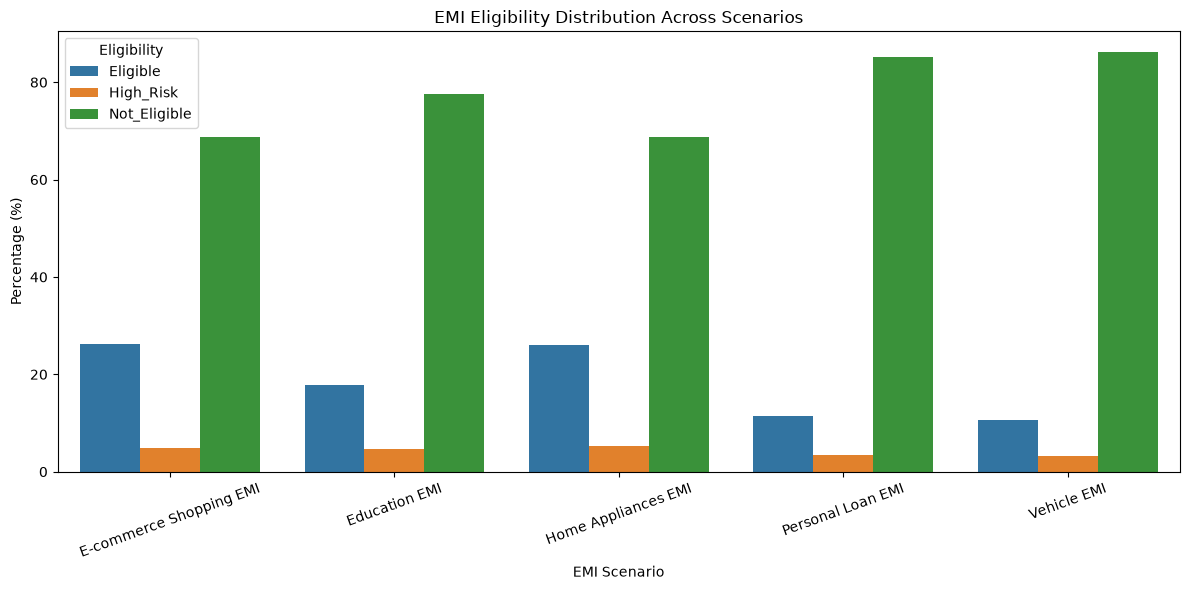

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

scenario_percentage = (pd.crosstab(df["emi_scenario"],df["emi_eligibility"],normalize="index").mul(100).round(2))

plt.figure(figsize=(12, 6))

sns.barplot(data=scenario_percentage.reset_index().melt(id_vars="emi_scenario",var_name="emi_eligibility",value_name="percentage"),
    x="emi_scenario",y="percentage",hue="emi_eligibility")

plt.title("EMI Eligibility Distribution Across Scenarios")
plt.xlabel("EMI Scenario")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=20)
plt.legend(title="Eligibility")
plt.tight_layout()
plt.show()

In [21]:
# Financial Variables vs EMI Eligibility

financial_columns = ["monthly_salary","current_emi_amount","credit_score","bank_balance","emergency_fund","requested_amount","max_monthly_emi"]

financial_by_eligibility = (df.groupby("emi_eligibility")[financial_columns].mean().round(2))

print("Average Financial Values by EMI Eligibility:")
print(financial_by_eligibility)

Average Financial Values by EMI Eligibility:
                 monthly_salary  current_emi_amount  credit_score  \
emi_eligibility                                                     
Eligible               78981.60             2405.85        725.62   
High_Risk              70300.78             3088.11        716.16   
Not_Eligible           54263.33             5133.36        694.11   

                 bank_balance  emergency_fund  requested_amount  \
emi_eligibility                                                   
Eligible            338517.53       135511.70         155361.20   
High_Risk           293574.89       118226.32         261358.25   
Not_Eligible        215392.21        86180.14         428250.65   

                 max_monthly_emi  
emi_eligibility                   
Eligible                15911.96  
High_Risk               11864.75  
Not_Eligible             4301.70  


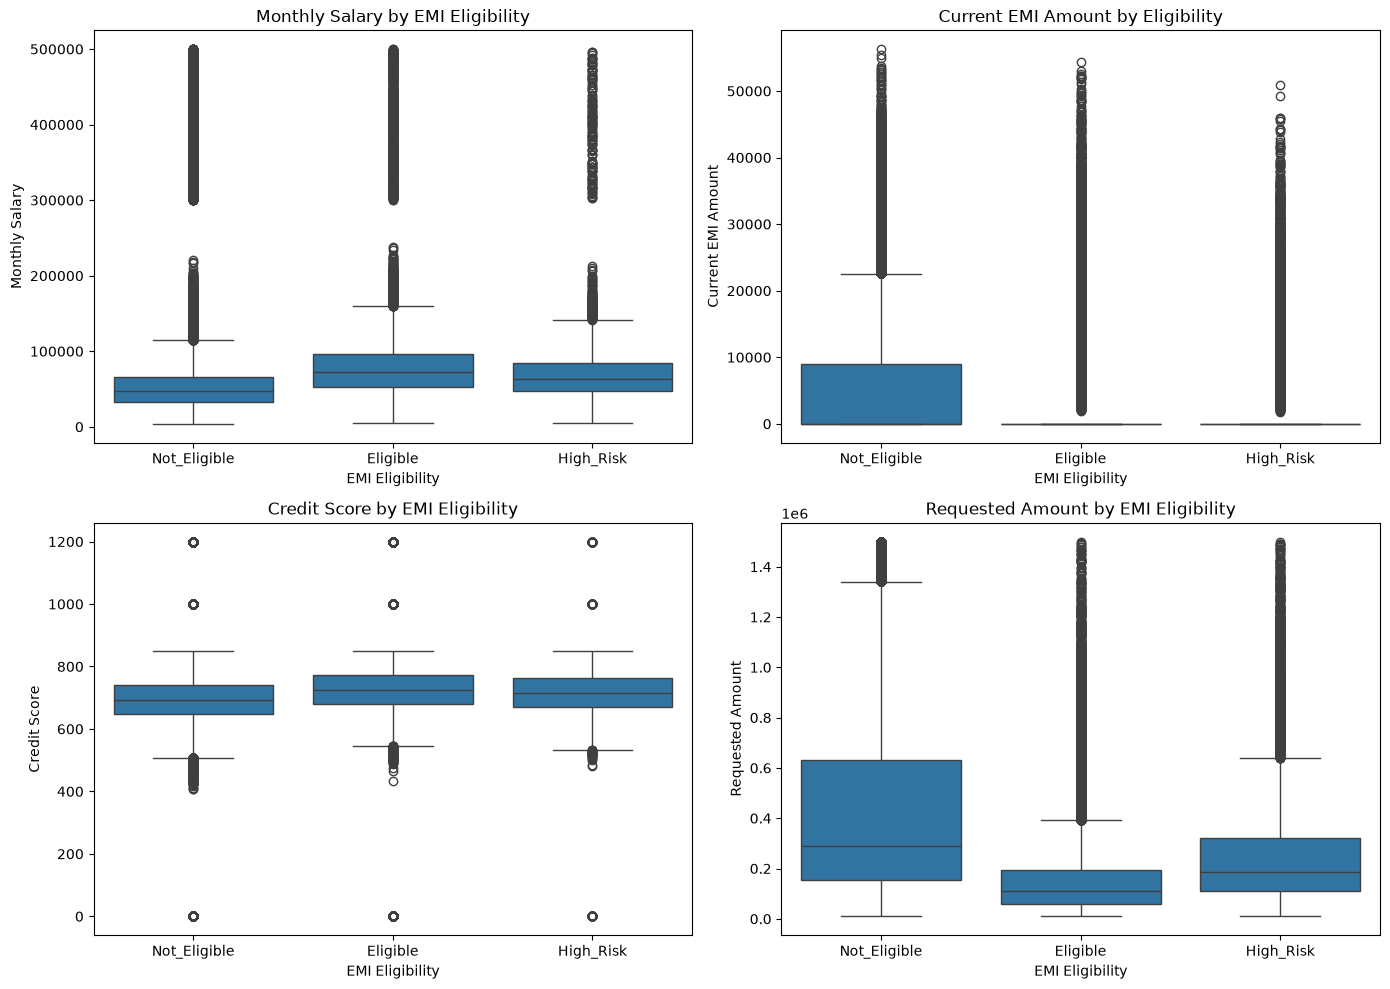

In [22]:
# Financial Variables vs EMI Eligibility

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(
    data=df,
    x="emi_eligibility",
    y="monthly_salary",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Monthly Salary by EMI Eligibility")
axes[0, 0].set_xlabel("EMI Eligibility")
axes[0, 0].set_ylabel("Monthly Salary")

sns.boxplot(
    data=df,
    x="emi_eligibility",
    y="current_emi_amount",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Current EMI Amount by Eligibility")
axes[0, 1].set_xlabel("EMI Eligibility")
axes[0, 1].set_ylabel("Current EMI Amount")

sns.boxplot(
    data=df,
    x="emi_eligibility",
    y="credit_score",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Credit Score by EMI Eligibility")
axes[1, 0].set_xlabel("EMI Eligibility")
axes[1, 0].set_ylabel("Credit Score")

sns.boxplot(
    data=df,
    x="emi_eligibility",
    y="requested_amount",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Requested Amount by EMI Eligibility")
axes[1, 1].set_xlabel("EMI Eligibility")
axes[1, 1].set_ylabel("Requested Amount")

plt.tight_layout()
plt.show()

In [23]:
# Demographic Patterns vs EMI Eligibility

demographic_columns = [
    "gender",
    "education",
    "employment_type",
    "house_type",
    "existing_loans"
]

for column in demographic_columns:

    print("\n" + "=" * 60)
    print(f"{column.upper()} VS EMI ELIGIBILITY")
    print("=" * 60)

    percentage_table = (
        pd.crosstab(
            df[column],
            df["emi_eligibility"],
            normalize="index"
        )
        .mul(100)
        .round(2)
    )

    print(percentage_table)


GENDER VS EMI ELIGIBILITY
emi_eligibility  Eligible  High_Risk  Not_Eligible
gender                                            
Female              18.39       4.32         77.29
Male                18.39       4.32         77.29

EDUCATION VS EMI ELIGIBILITY
emi_eligibility  Eligible  High_Risk  Not_Eligible
education                                         
Graduate            15.72       4.04         80.23
High School         11.11       3.24         85.65
Post Graduate       22.45       4.91         72.64
Professional        27.08       5.27         67.65

EMPLOYMENT_TYPE VS EMI ELIGIBILITY
emi_eligibility  Eligible  High_Risk  Not_Eligible
employment_type                                   
Government          21.40       4.61         73.99
Private             17.80       4.27         77.94
Self-employed       16.52       4.09         79.39

HOUSE_TYPE VS EMI ELIGIBILITY
emi_eligibility  Eligible  High_Risk  Not_Eligible
house_type                                        
Family   

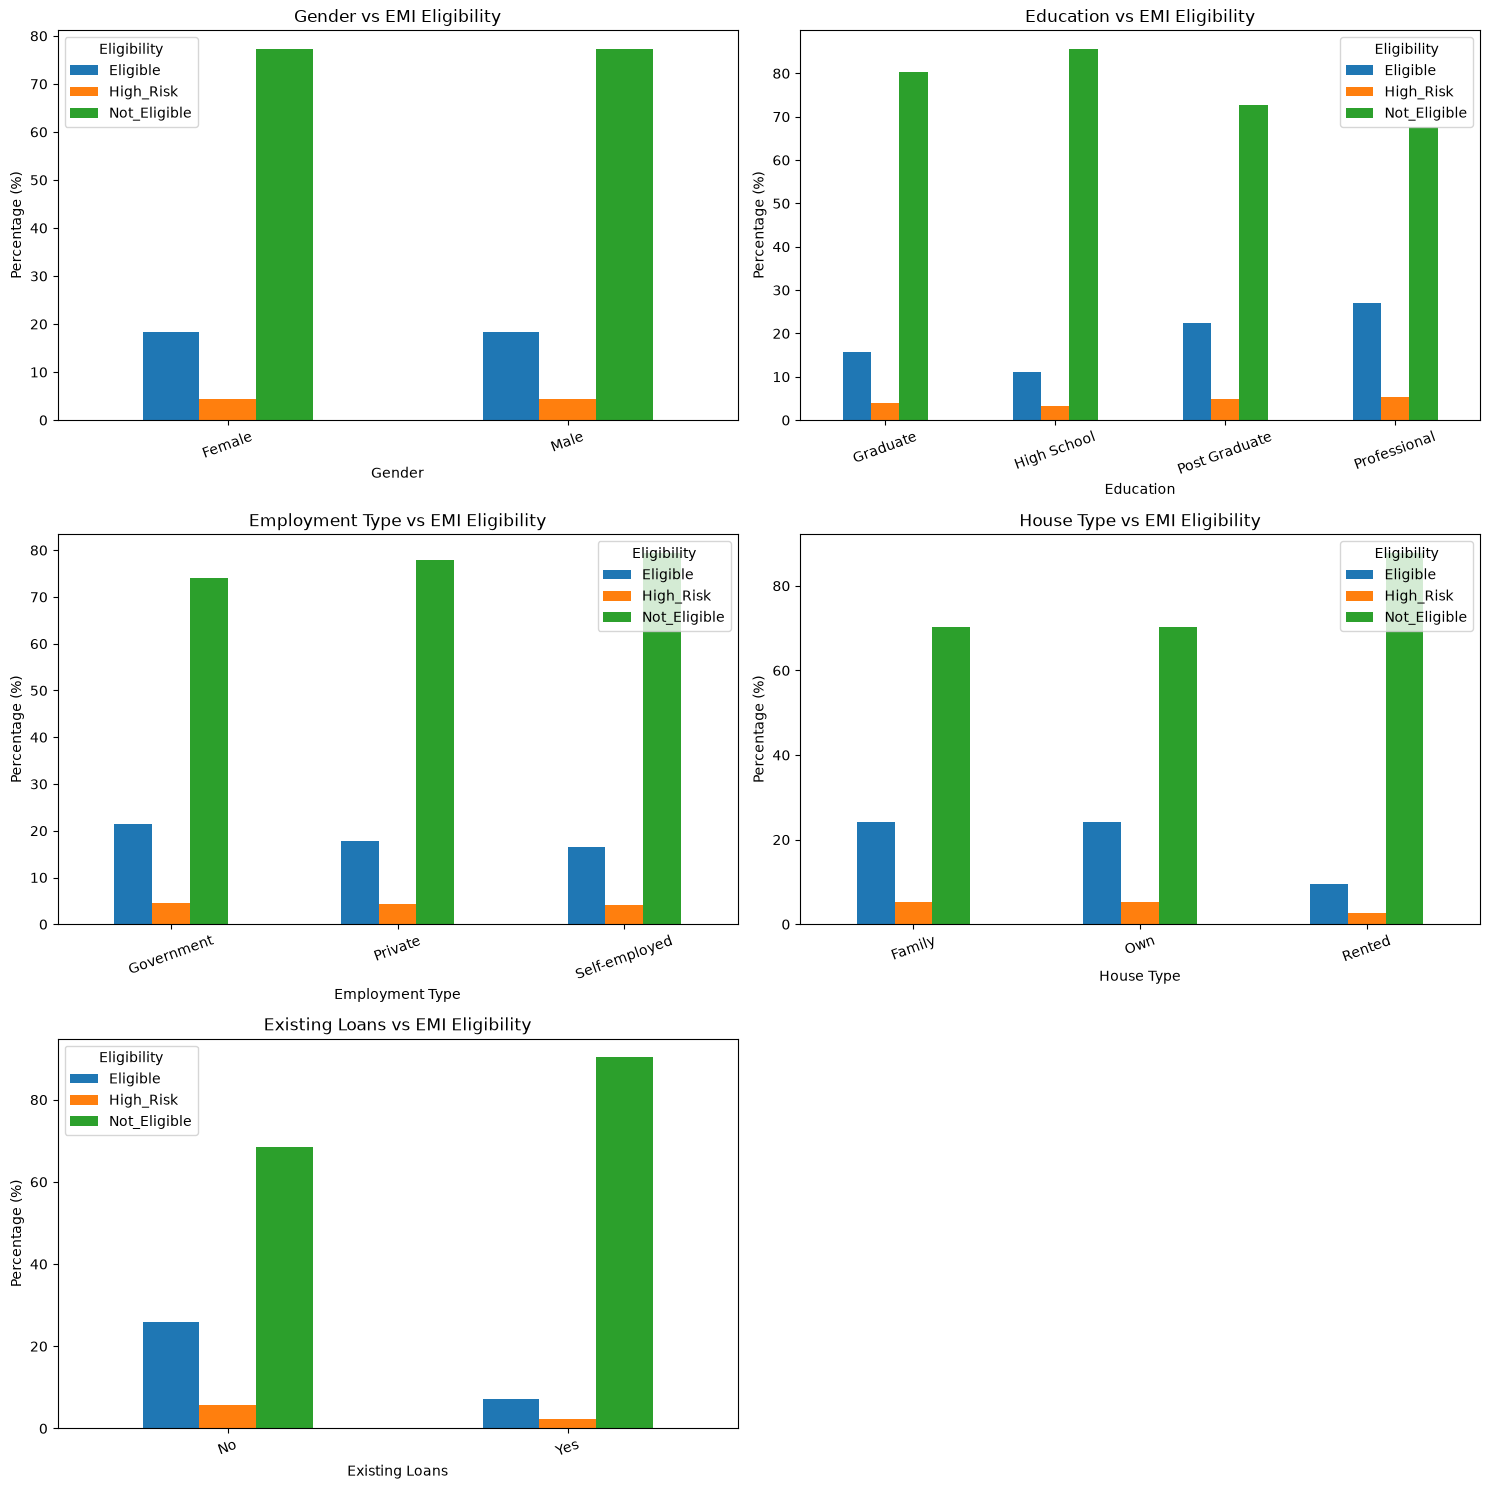

In [24]:
# Categorical Variables vs EMI Eligibility

fig, axes = plt.subplots(3, 2, figsize=(15, 15))

categorical_columns = [
    "gender",
    "education",
    "employment_type",
    "house_type",
    "existing_loans"
]

for ax, column in zip(axes.flat, categorical_columns):

    percentage_table = (
        pd.crosstab(
            df[column],
            df["emi_eligibility"],
            normalize="index"
        )
        .mul(100)
    )

    percentage_table.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(f"{column.replace('_', ' ').title()} vs EMI Eligibility")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Percentage (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Eligibility")

# Hide unused subplot
axes[2, 1].set_visible(False)

plt.tight_layout()
plt.show()


Correlation with Max Monthly EMI:
max_monthly_emi           1.000
groceries_utilities       0.485
bank_balance              0.457
travel_expenses           0.441
emergency_fund            0.414
other_monthly_expenses    0.382
monthly_salary            0.379
credit_score              0.229
years_of_employment       0.029
requested_tenure          0.001
age                      -0.001
requested_amount         -0.002
dependents               -0.062
family_size              -0.062
monthly_rent             -0.169
school_fees              -0.215
current_emi_amount       -0.242
college_fees             -0.259
Name: max_monthly_emi, dtype: float64


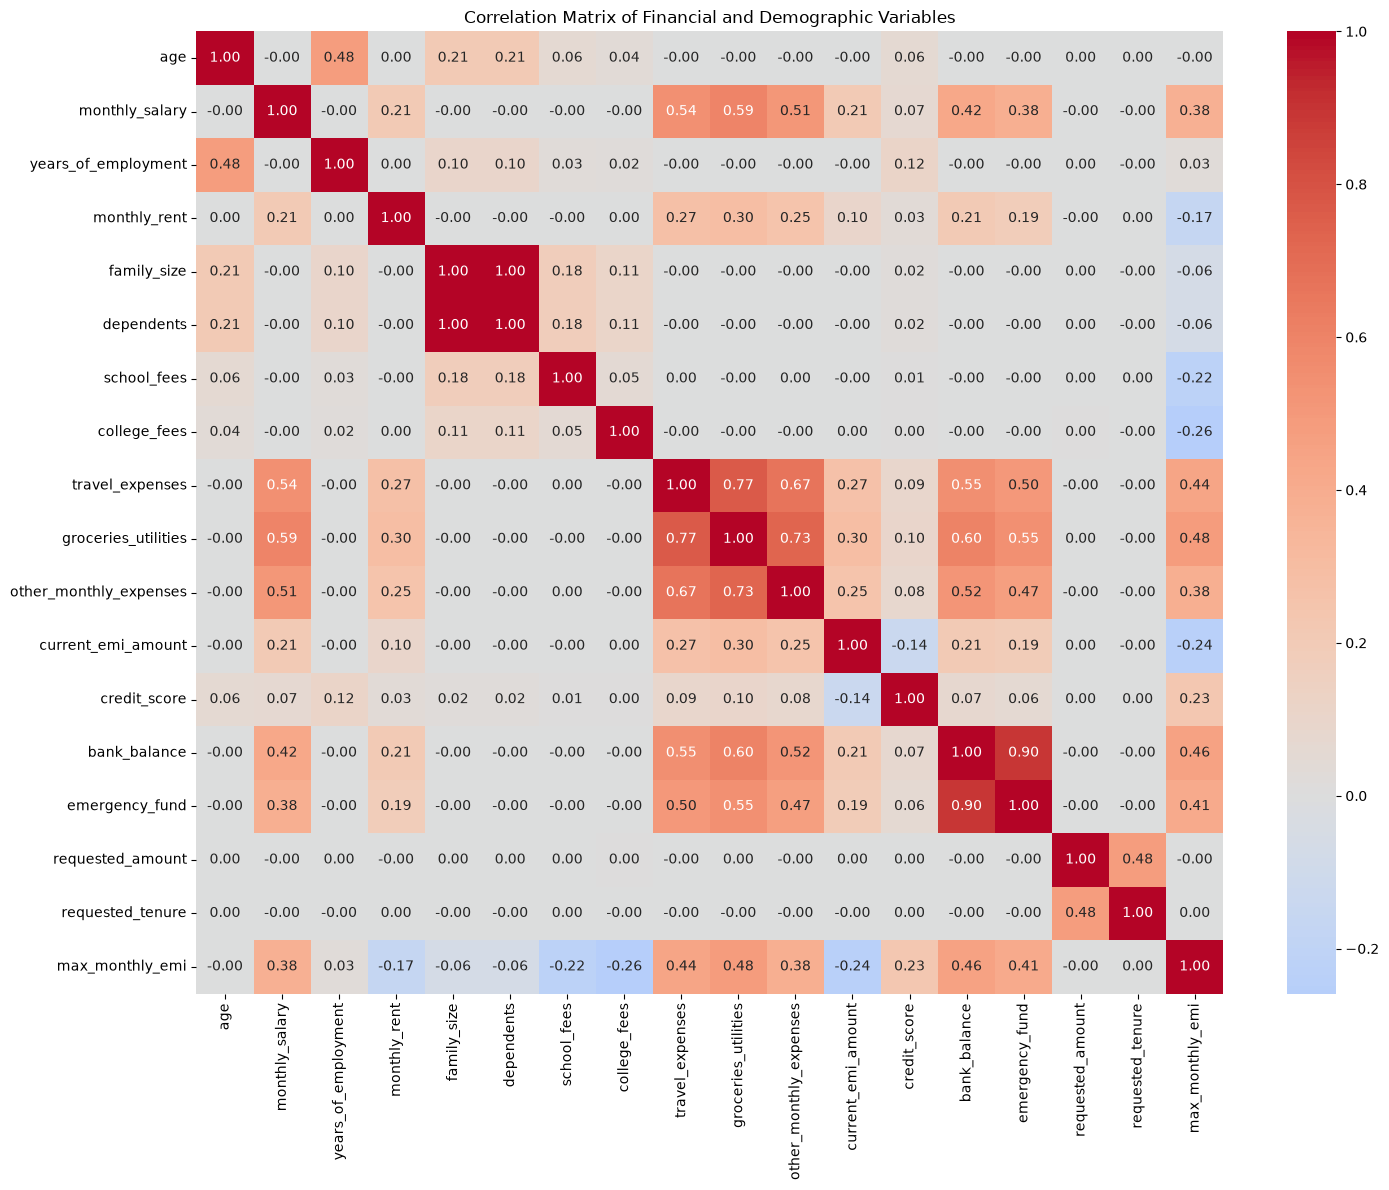

In [25]:
# Correlation Analysis of Numerical Variables

numerical_columns = ["age","monthly_salary","years_of_employment","monthly_rent","family_size","dependents","school_fees",
    "college_fees","travel_expenses","groceries_utilities","other_monthly_expenses","current_emi_amount","credit_score",
    "bank_balance","emergency_fund","requested_amount","requested_tenure","max_monthly_emi"]

correlation_matrix = df[numerical_columns].corr()

print("Correlation with Max Monthly EMI:")
print(correlation_matrix["max_monthly_emi"].sort_values(ascending=False).round(3))

plt.figure(figsize=(15, 12))

sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap="coolwarm",center=0)

plt.title("Correlation Matrix of Financial and Demographic Variables")
plt.tight_layout()
plt.show()

In [26]:
# Check for Highly Correlated Numerical Features

feature_columns = ["age","monthly_salary", "years_of_employment","monthly_rent","family_size","dependents","school_fees","college_fees",
    "travel_expenses","groceries_utilities","other_monthly_expenses","current_emi_amount","credit_score","bank_balance",
    "emergency_fund","requested_amount","requested_tenure"]

feature_correlation = df[feature_columns].corr()

high_correlations = []

for i in range(len(feature_columns)):
    for j in range(i + 1, len(feature_columns)):

        correlation = feature_correlation.iloc[i, j]

        if abs(correlation) >= 0.70:
            high_correlations.append(
                (
                    feature_columns[i],
                    feature_columns[j],
                    round(correlation, 3)
                )
            )

print("Highly correlated feature pairs (|correlation| >= 0.70):")

if high_correlations:
    for pair in high_correlations:
        print(pair)
else:
    print("No feature pairs have correlation >= 0.70.")

Highly correlated feature pairs (|correlation| >= 0.70):
('family_size', 'dependents', np.float64(1.0))
('travel_expenses', 'groceries_utilities', np.float64(0.772))
('groceries_utilities', 'other_monthly_expenses', np.float64(0.727))
('bank_balance', 'emergency_fund', np.float64(0.896))


In [ ]:
###############################step 3#############################

In [27]:
# Step 3: Feature Engineering
# Core Financial Features

df["total_education_expenses"] = (df["school_fees"] + df["college_fees"])
df["total_living_expenses"] = (df["monthly_rent"] + df["travel_expenses"] + df["groceries_utilities"] + df["other_monthly_expenses"])
df["total_monthly_expenses"] = (df["total_living_expenses"] + df["total_education_expenses"])
df["total_financial_reserves"] = (df["bank_balance"] +df["emergency_fund"])

# Avoid division by zero
income = df["monthly_salary"].replace(0, 1)

# Debt-to-Income Ratio
df["debt_to_income_ratio"] = (df["current_emi_amount"] / income)

# Expense-to-Income Ratio
df["expense_to_income_ratio"] = (df["total_monthly_expenses"] / income)

# Current EMI-to-Income Ratio
df["emi_to_income_ratio"] = (df["current_emi_amount"] / income)

# Affordability Ratio
df["affordability_ratio"] = ((df["monthly_salary"] - df["total_monthly_expenses"] - df["current_emi_amount"]) / income)

# Disposable income after current financial commitments
df["disposable_income"] = (df["monthly_salary"]- df["total_monthly_expenses"]- df["current_emi_amount"])

print("New engineered features:")
print([ "total_education_expenses", "total_living_expenses","total_monthly_expenses","total_financial_reserves",
        "debt_to_income_ratio","expense_to_income_ratio","emi_to_income_ratio","affordability_ratio","disposable_income"])

print("\nFeature summary:")
print(df[["total_education_expenses","total_living_expenses","total_monthly_expenses","total_financial_reserves",
          "debt_to_income_ratio","expense_to_income_ratio","emi_to_income_ratio","affordability_ratio","disposable_income"]].describe().round(3)
)

New engineered features:
['total_education_expenses', 'total_living_expenses', 'total_monthly_expenses', 'total_financial_reserves', 'debt_to_income_ratio', 'expense_to_income_ratio', 'emi_to_income_ratio', 'affordability_ratio', 'disposable_income']

Feature summary:
       total_education_expenses  total_living_expenses  \
count                404800.000             404800.000   
mean                   8690.829              31405.323   
std                    9122.943              18157.713   
min                       0.000               3300.000   
25%                       0.000              18200.000   
50%                    6800.000              27400.000   
75%                   13600.000              40200.000   
max                   40000.000             189300.000   

       total_monthly_expenses  total_financial_reserves  debt_to_income_ratio  \
count              404800.000                404800.000            404800.000   
mean                40096.152                3

In [28]:
# Validate Extreme Engineered Ratios

print("Debt-to-Income Ratio:")
print(df["debt_to_income_ratio"].describe(percentiles=[0.90, 0.95, 0.99, 0.995, 0.999]).round(3))

print("\nExpense-to-Income Ratio:")
print(df["expense_to_income_ratio"].describe(percentiles=[0.90, 0.95, 0.99, 0.995, 0.999]).round(3))

print("\nAffordability Ratio:")
print(df["affordability_ratio"].describe(percentiles=[0.01, 0.005, 0.001]).round(3))

print("\nExtreme value counts:")
print("\nDebt-to-Income > 1:",(df["debt_to_income_ratio"] > 1).sum())
print("Expense-to-Income > 1:",(df["expense_to_income_ratio"] > 1).sum())
print("Expense-to-Income > 2:",(df["expense_to_income_ratio"] > 2).sum())

print( "Negative Disposable Income:",(df["disposable_income"] < 0).sum())

print("Negative Affordability Ratio:",(df["affordability_ratio"] < 0).sum())

Debt-to-Income Ratio:
count    404800.000
mean          0.084
std           0.142
min           0.000
90%           0.251
95%           0.276
99%           0.297
99.5%         0.299
99.9%         1.687
max           7.704
Name: debt_to_income_ratio, dtype: float64

Expense-to-Income Ratio:
count    404800.000
mean          0.784
std           0.578
min           0.011
90%           1.140
95%           1.358
99%           2.289
99.5%         4.002
99.9%         8.628
max          26.777
Name: expense_to_income_ratio, dtype: float64

Affordability Ratio:
count    404800.000
mean          0.133
std           0.637
min         -30.292
0.1%         -8.487
0.5%         -3.453
1%           -1.406
max           0.989
Name: affordability_ratio, dtype: float64

Extreme value counts:

Debt-to-Income > 1: 849
Expense-to-Income > 1: 66422
Expense-to-Income > 2: 5504
Negative Disposable Income: 97491
Negative Affordability Ratio: 97491


In [29]:
# Inspect Extreme Financial Ratio Cases

print("Top 10 highest Debt-to-Income ratios:")
print(df[["monthly_salary", "current_emi_amount","debt_to_income_ratio","emi_eligibility"]].sort_values("debt_to_income_ratio", ascending=False)
    .head(10))

print("\n" + "=" * 70)

print("Top 10 highest Expense-to-Income ratios:")
print(df[["monthly_salary","total_monthly_expenses","expense_to_income_ratio","emi_eligibility"]]
    .sort_values("expense_to_income_ratio", ascending=False)
    .head(10))

print("\n" + "=" * 70)

print("Top 10 lowest Affordability ratios:")
print(df[["monthly_salary","total_monthly_expenses", "current_emi_amount","disposable_income","affordability_ratio","emi_eligibility"]]
    .sort_values("affordability_ratio")
    .head(10))

Top 10 highest Debt-to-Income ratios:
        monthly_salary  current_emi_amount  debt_to_income_ratio  \
301700          5062.0             39000.0              7.704465   
38324           5400.0             40200.0              7.444444   
64100           6228.0             40800.0              6.551060   
231748          6072.0             37000.0              6.093544   
220503          5124.0             29700.0              5.796253   
276126          5089.0             28800.0              5.659265   
38458           5084.0             28500.0              5.605822   
193367          5132.0             26900.0              5.241621   
161890          5431.0             27800.0              5.118763   
99230           5278.0             26000.0              4.926108   

       emi_eligibility  
301700    Not_Eligible  
38324         Eligible  
64100        High_Risk  
231748    Not_Eligible  
220503        Eligible  
276126    Not_Eligible  
38458     Not_Eligible  
193367    Not

In [30]:
# Credit Risk and Employment Stability Features

# --------------------------------------------------
# 1. Credit Risk Category
# --------------------------------------------------

df["credit_risk_category"] = pd.cut(df["credit_score"], bins=[-float("inf"), 579, 669, 739, 799, float("inf")],
                                    labels=[ "Very_High_Risk","High_Risk","Moderate_Risk","Low_Risk","Very_Low_Risk"],
                                    include_lowest=True)

# --------------------------------------------------
# 2. Credit Risk Score
# Higher score = lower credit risk
# --------------------------------------------------

credit_risk_mapping = {"Very_High_Risk": 1,"High_Risk": 2,"Moderate_Risk": 3,"Low_Risk": 4,"Very_Low_Risk": 5}
df["credit_risk_score"] = (df["credit_risk_category"].astype(str).map(credit_risk_mapping))

# --------------------------------------------------
# 3. Employment Stability Category
# --------------------------------------------------

df["employment_stability_category"] = pd.cut(df["years_of_employment"],bins=[-float("inf"), 1, 3, 5, 10, float("inf")],
    labels=["Very_Low_Stability","Low_Stability","Moderate_Stability","High_Stability","Very_High_Stability"],include_lowest=True)

# --------------------------------------------------
# 4. Employment Stability Score
# Higher score = greater stability
# --------------------------------------------------

employment_stability_mapping = {"Very_Low_Stability": 1,"Low_Stability": 2,"Moderate_Stability": 3,
                                "High_Stability": 4,"Very_High_Stability": 5}

df["employment_stability_score"] = (df["employment_stability_category"].astype(str).map(employment_stability_mapping))

# --------------------------------------------------
# Check results
# --------------------------------------------------

print("Credit Risk Category:")
print(df["credit_risk_category"].value_counts().sort_index())

print("\nCredit Risk Score:")
print(df["credit_risk_score"].value_counts().sort_index())

print("\nEmployment Stability Category:")
print(df["employment_stability_category"].value_counts().sort_index())

print("\nEmployment Stability Score:")
print(df["employment_stability_score"].value_counts().sort_index())

Credit Risk Category:
credit_risk_category
Very_High_Risk     16661
High_Risk         114972
Moderate_Risk     156185
Low_Risk           83200
Very_Low_Risk      33782
Name: count, dtype: int64

Credit Risk Score:
credit_risk_score
1     16661
2    114972
3    156185
4     83200
5     33782
Name: count, dtype: int64

Employment Stability Category:
employment_stability_category
Very_Low_Stability      90076
Low_Stability          107624
Moderate_Stability      65837
High_Stability          79911
Very_High_Stability     61352
Name: count, dtype: int64

Employment Stability Score:
employment_stability_score
1     90076
2    107624
3     65837
4     79911
5     61352
Name: count, dtype: int64


In [31]:
# Interaction Features

# 1. Income adjusted by credit risk
df["income_credit_risk_interaction"] = (df["monthly_salary"] * df["credit_risk_score"])

# 2. Income adjusted by employment stability
df["income_employment_stability_interaction"] = (df["monthly_salary"] * df["employment_stability_score"])

# 3. Financial reserves adjusted by credit risk
df["reserve_credit_risk_interaction"] = (df["total_financial_reserves"] * df["credit_risk_score"])

# 4. Combined financial stability interaction
df["financial_stability_interaction"] = (df["credit_risk_score"]* df["employment_stability_score"])

# 5. Requested amount relative to financial reserves
df["requested_to_reserve_ratio"] = (df["requested_amount"] / df["total_financial_reserves"].replace(0, 1))

# 6. Requested amount relative to income
df["requested_to_income_ratio"] = (df["requested_amount"]/ df["monthly_salary"].replace(0, 1))

# Display newly created interaction features
interaction_features = [ "income_credit_risk_interaction","income_employment_stability_interaction","reserve_credit_risk_interaction",
    "financial_stability_interaction","requested_to_reserve_ratio","requested_to_income_ratio"]

print("Interaction features created:")
print(interaction_features)

print("\nInteraction feature summary:")
print(df[interaction_features].describe().round(3))

Interaction features created:
['income_credit_risk_interaction', 'income_employment_stability_interaction', 'reserve_credit_risk_interaction', 'financial_stability_interaction', 'requested_to_reserve_ratio', 'requested_to_income_ratio']

Interaction feature summary:
       income_credit_risk_interaction  \
count                      404800.000   
mean                       182498.976   
std                        155934.279   
min                          5002.000   
25%                         90400.000   
50%                        143200.000   
75%                        228400.000   
max                       2482270.000   

       income_employment_stability_interaction  \
count                               404800.000   
mean                                165871.943   
std                                 157983.552   
min                                   3967.000   
25%                                  70400.000   
50%                                 126400.000   
75%          

In [34]:
# Final Feature Engineering Audit

# Remove duplicate engineered feature
df.drop(columns=["emi_to_income_ratio"],inplace=True)

# Separate targets
target_columns = ["emi_eligibility","max_monthly_emi"]

# Identify features
feature_columns = [column
    for column in df.columns
    if column not in target_columns
]

print("Dataset shape:", df.shape)

print("\nNumber of features:", len(feature_columns))

print("\nFeature columns:")
for i, column in enumerate(feature_columns, start=1):
    print(f"{i}. {column}")

print("\nTarget columns:")
print(target_columns)

print("\nMissing values:")
print(df[feature_columns + target_columns].isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df[feature_columns].dtypes)

print("\nFinal target distributions:")

print("\nClassification target:")
print(df["emi_eligibility"].value_counts())

print("\nRegression target:")
print(df["max_monthly_emi"].describe().round(2))

Dataset shape: (404800, 45)

Number of features: 43

Feature columns:
1. age
2. gender
3. marital_status
4. education
5. monthly_salary
6. employment_type
7. years_of_employment
8. company_type
9. house_type
10. monthly_rent
11. family_size
12. dependents
13. school_fees
14. college_fees
15. travel_expenses
16. groceries_utilities
17. other_monthly_expenses
18. existing_loans
19. current_emi_amount
20. credit_score
21. bank_balance
22. emergency_fund
23. emi_scenario
24. requested_amount
25. requested_tenure
26. total_education_expenses
27. total_living_expenses
28. total_monthly_expenses
29. total_financial_reserves
30. debt_to_income_ratio
31. expense_to_income_ratio
32. affordability_ratio
33. disposable_income
34. credit_risk_category
35. credit_risk_score
36. employment_stability_category
37. employment_stability_score
38. income_credit_risk_interaction
39. income_employment_stability_interaction
40. reserve_credit_risk_interaction
41. financial_stability_interaction
42. requested

In [35]:
#########################step 4###################
# Step 4: ML Model Development
# Classification Dataset + Preprocessing Setup

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# --------------------------------------------------
# 1. Separate features and classification target
# --------------------------------------------------

X = df.drop(columns=["emi_eligibility", "max_monthly_emi"])
y = df["emi_eligibility"]

# --------------------------------------------------
# 2. Train / Validation / Test Split
# --------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split( X,y,test_size=0.30,random_state=42,stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,test_size=0.50,random_state=42,stratify=y_temp)

# --------------------------------------------------
# 3. Identify numerical and categorical features
# --------------------------------------------------

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

# --------------------------------------------------
# 4. Numerical preprocessing
# --------------------------------------------------

numeric_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

# --------------------------------------------------
# 5. Categorical preprocessing
# --------------------------------------------------

categorical_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=True))])

# --------------------------------------------------
# 6. Combined preprocessing
# --------------------------------------------------

preprocessor = ColumnTransformer(transformers=[("num", numeric_pipeline, numerical_features),
                                               ("cat", categorical_pipeline, categorical_features)])

print("\nPreprocessing pipeline created successfully.")

Training shape: (283360, 43)
Validation shape: (60720, 43)
Test shape: (60720, 43)

Number of numerical features: 33
Number of categorical features: 10

Categorical features:
['gender', 'marital_status', 'education', 'employment_type', 'company_type', 'house_type', 'existing_loans', 'emi_scenario', 'credit_risk_category', 'employment_stability_category']

Numerical features:
['age', 'monthly_salary', 'years_of_employment', 'monthly_rent', 'family_size', 'dependents', 'school_fees', 'college_fees', 'travel_expenses', 'groceries_utilities', 'other_monthly_expenses', 'current_emi_amount', 'credit_score', 'bank_balance', 'emergency_fund', 'requested_amount', 'requested_tenure', 'total_education_expenses', 'total_living_expenses', 'total_monthly_expenses', 'total_financial_reserves', 'debt_to_income_ratio', 'expense_to_income_ratio', 'affordability_ratio', 'disposable_income', 'credit_risk_score', 'employment_stability_score', 'income_credit_risk_interaction', 'income_employment_stability_i

/var/folders/q4/20nw8rv90kg9q755z7sstw780000gn/T/ipykernel_1155/3931811243.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


In [57]:
# Step 4A: Logistic Regression Baseline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report)

# --------------------------------------------------
# 1. Create Logistic Regression pipeline
# --------------------------------------------------

logistic_model = Pipeline(steps=[("preprocessor", preprocessor),
                                 ("classifier",LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42))])

# --------------------------------------------------
# 2. Train the model
# --------------------------------------------------

print("Training Logistic Regression...")

logistic_model.fit(X_train,y_train)

print("Training completed.")

# --------------------------------------------------
# 3. Validation predictions
# --------------------------------------------------

y_val_pred = logistic_model.predict(X_val)
y_val_proba = logistic_model.predict_proba(X_val)

# --------------------------------------------------
# 4. Calculate validation metrics
# --------------------------------------------------

logistic_accuracy = accuracy_score(y_val,y_val_pred)
logistic_precision = precision_score(y_val,y_val_pred,average="macro",zero_division=0)
logistic_recall = recall_score(y_val,y_val_pred,average="macro",zero_division=0)
logistic_f1 = f1_score(y_val,y_val_pred,average="macro",zero_division=0)
logistic_roc_auc = roc_auc_score(y_val,y_val_proba,multi_class="ovr",average="macro")

# --------------------------------------------------
# 5. Print metrics
# --------------------------------------------------

print("\n" + "=" * 60)
print("LOGISTIC REGRESSION - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_val,y_val_pred,zero_division=0))

Training Logistic Regression...
Training completed.

LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy : 0.7970
Precision: 0.6577
Recall   : 0.7491
F1 Score : 0.6440
ROC-AUC  : 0.9312

Classification Report:
              precision    recall  f1-score   support

    Eligible       0.84      0.76      0.80     11166
   High_Risk       0.15      0.67      0.24      2623
Not_Eligible       0.99      0.81      0.89     46931

    accuracy                           0.80     60720
   macro avg       0.66      0.75      0.64     60720
weighted avg       0.92      0.80      0.85     60720



In [38]:
# Step 4B: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report)


# --------------------------------------------------
# 1. Create Random Forest pipeline
# --------------------------------------------------

random_forest_model = Pipeline(steps=[("preprocessor", preprocessor),
                                      ("classifier",RandomForestClassifier(n_estimators=200,max_depth=20,
                                                                           min_samples_split=10,class_weight="balanced",
                                                                           random_state=42,n_jobs=-1))])

# --------------------------------------------------
# 2. Train the model
# --------------------------------------------------

print("Training Random Forest Classifier...")
random_forest_model.fit(X_train,y_train)
print("Training completed.")

# --------------------------------------------------
# 3. Validation predictions
# --------------------------------------------------

rf_val_pred = random_forest_model.predict(X_val)
rf_val_proba = random_forest_model.predict_proba(X_val)

# --------------------------------------------------
# 4. Calculate validation metrics
# --------------------------------------------------

rf_accuracy = accuracy_score(y_val,rf_val_pred)
rf_precision = precision_score(y_val,rf_val_pred,average="macro",zero_division=0)
rf_recall = recall_score(y_val,rf_val_pred,average="macro",zero_division=0)
rf_f1 = f1_score(y_val,rf_val_pred,average="macro",zero_division=0)
rf_roc_auc = roc_auc_score(y_val,rf_val_proba,multi_class="ovr",average="macro")

# --------------------------------------------------
# 5. Print results
# --------------------------------------------------

print("\n" + "=" * 60)
print("RANDOM FOREST - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_val,rf_val_pred,zero_division=0))

Training Random Forest Classifier...
Training completed.

RANDOM FOREST - VALIDATION RESULTS
Accuracy : 0.9165
Precision: 0.7274
Recall   : 0.8062
F1 Score : 0.7561
ROC-AUC  : 0.9735

Classification Report:
              precision    recall  f1-score   support

    Eligible       0.86      0.92      0.89     11166
   High_Risk       0.33      0.56      0.42      2623
Not_Eligible       0.99      0.94      0.96     46931

    accuracy                           0.92     60720
   macro avg       0.73      0.81      0.76     60720
weighted avg       0.94      0.92      0.93     60720



In [39]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 11.5 MB/s  0:00:002.8 MB/s eta 0:00:01


In [46]:
# Step 4C: XGBoost Classifier

from xgboost import XGBClassifier

# --------------------------------------------------
# 1. Convert target labels to numeric classes
# --------------------------------------------------

class_mapping = { "Not_Eligible": 0,"Eligible": 1,"High_Risk": 2}
y_train_xgb = y_train.map(class_mapping)
y_val_xgb = y_val.map(class_mapping)

# --------------------------------------------------
# 2. Create XGBoost pipeline
# --------------------------------------------------

xgb_model = Pipeline(steps=[("preprocessor", preprocessor),
                            ("classifier",XGBClassifier(n_estimators=200,max_depth=8,learning_rate=0.1,
                                                        subsample=0.8,colsample_bytree=0.8,objective="multi:softprob",
                                                        num_class=3,eval_metric="mlogloss",random_state=42,n_jobs=-1))])
# --------------------------------------------------
# 3. Train the model
# --------------------------------------------------

print("Training XGBoost Classifier...")

xgb_model.fit(X_train,y_train_xgb)

print("Training completed.")

# --------------------------------------------------
# 4. Validation predictions
# --------------------------------------------------

xgb_val_pred_numeric = xgb_model.predict(X_val)
xgb_val_proba = xgb_model.predict_proba(X_val)

# Convert numeric predictions back to original labels
reverse_mapping = {0: "Not_Eligible",1: "Eligible",2: "High_Risk"}

xgb_val_pred = pd.Series(xgb_val_pred_numeric,index=y_val.index).map(reverse_mapping)

# --------------------------------------------------
# 5. Calculate validation metrics
# --------------------------------------------------

xgb_accuracy = accuracy_score(y_val,xgb_val_pred)
xgb_precision = precision_score(y_val,xgb_val_pred,average="macro",zero_division=0)
xgb_recall = recall_score(y_val,xgb_val_pred,average="macro",zero_division=0)
xgb_f1 = f1_score(y_val,xgb_val_pred,average="macro",zero_division=0)
xgb_roc_auc = roc_auc_score(y_val_xgb,xgb_val_proba,multi_class="ovr",average="macro")

# --------------------------------------------------
# 6. Print results
# --------------------------------------------------

print("\n" + "=" * 60)
print("XGBOOST CLASSIFIER - VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_val,xgb_val_pred,zero_division=0))

Training XGBoost Classifier...
Training completed.

XGBOOST CLASSIFIER - VALIDATION RESULTS
Accuracy : 0.9713
Precision: 0.9103
Recall   : 0.8295
F1 Score : 0.8597
ROC-AUC  : 0.9936

Classification Report:
              precision    recall  f1-score   support

    Eligible       0.95      0.98      0.96     11166
   High_Risk       0.80      0.52      0.63      2623
Not_Eligible       0.98      1.00      0.99     46931

    accuracy                           0.97     60720
   macro avg       0.91      0.83      0.86     60720
weighted avg       0.97      0.97      0.97     60720



In [45]:
# Classification Model Comparison

classification_results = pd.DataFrame({"Model": [ "Logistic Regression","Random Forest","XGBoost"],
                                       "Accuracy": [0.7970,0.9165,0.9713],
                                       "Precision": [0.6577,0.7274,0.9103],
                                       "Recall": [0.7491,0.8062,0.8295],
                                       "F1 Score": [0.6440,0.7561,0.8597],
                                       "ROC-AUC": [0.9312,0.9735,0.9936]})

print("=" * 70)
print("CLASSIFICATION MODEL COMPARISON")
print("=" * 70)

display(classification_results)

CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7970,0.6577,0.7491,0.6440,0.9312
1,Random Forest,0.9165,0.7274,0.8062,0.7561,0.9735
2,XGBoost,0.9713,0.9103,0.8295,0.8597,0.9936


In [47]:
# Step 4D: Regression Data Split

from sklearn.model_selection import train_test_split

# Features and regression target
X_reg = df.drop(columns=["emi_eligibility", "max_monthly_emi"])
y_reg = df["max_monthly_emi"]

# 70% Train, 15% Validation, 15% Test
X_reg_train, X_reg_temp, y_reg_train, y_reg_temp = train_test_split(X_reg,y_reg,test_size=0.30,random_state=42)
X_reg_val, X_reg_test, y_reg_val, y_reg_test = train_test_split(X_reg_temp,y_reg_temp,test_size=0.50,random_state=42)

print("=" * 60)
print("REGRESSION DATA SPLIT")
print("=" * 60)

print("Training :", X_reg_train.shape)
print("Validation:", X_reg_val.shape)
print("Testing  :", X_reg_test.shape)

print("\nTarget statistics:")
print(y_reg_train.describe())

REGRESSION DATA SPLIT
Training : (283360, 43)
Validation: (60720, 43)
Testing  : (60720, 43)

Target statistics:
count    283360.000000
mean       6771.310971
std        7747.941824
min         500.000000
25%         500.000000
50%        4218.060000
75%        9792.000000
max       89166.000000
Name: max_monthly_emi, dtype: float64


In [48]:
# Step 4D.1: Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (mean_squared_error,mean_absolute_error,r2_score)
import numpy as np

# --------------------------------------------------
# 1. Identify numerical and categorical features
# --------------------------------------------------

numerical_features_reg = X_reg_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features_reg = X_reg_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()

print("Numerical features:", len(numerical_features_reg))
print("Categorical features:", len(categorical_features_reg))

# --------------------------------------------------
# 2. Create preprocessing pipelines
# --------------------------------------------------

numeric_pipeline_reg = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

categorical_pipeline_reg = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                     ("onehot", OneHotEncoder(handle_unknown="ignore",sparse_output=True))])

reg_preprocessor = ColumnTransformer([("num", numeric_pipeline_reg, numerical_features_reg),
                                      ("cat", categorical_pipeline_reg, categorical_features_reg)])

# --------------------------------------------------
# 3. Create Linear Regression pipeline
# --------------------------------------------------

linear_regression_model = Pipeline([("preprocessor", reg_preprocessor),("regressor", LinearRegression())])

# --------------------------------------------------
# 4. Train model
# --------------------------------------------------

print("\nTraining Linear Regression...")

linear_regression_model.fit(X_reg_train,y_reg_train)

print("Training completed.")

# --------------------------------------------------
# 5. Validation predictions
# --------------------------------------------------

linear_val_pred = linear_regression_model.predict(X_reg_val)

# --------------------------------------------------
# 6. Calculate regression metrics
# --------------------------------------------------

linear_rmse = np.sqrt(mean_squared_error(y_reg_val, linear_val_pred))
linear_mae = mean_absolute_error(y_reg_val,linear_val_pred)
linear_r2 = r2_score(y_reg_val,linear_val_pred)

# Avoid division by zero for MAPE
non_zero_mask = y_reg_val != 0
linear_mape = np.mean(np.abs((y_reg_val[non_zero_mask] - linear_val_pred[non_zero_mask]) / y_reg_val[non_zero_mask])) * 100

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------

print("\n" + "=" * 60)
print("LINEAR REGRESSION - VALIDATION RESULTS")
print("=" * 60)

print(f"RMSE : {linear_rmse:.2f}")
print(f"MAE  : {linear_mae:.2f}")
print(f"R²   : {linear_r2:.4f}")
print(f"MAPE : {linear_mape:.2f}%")

Numerical features: 33
Categorical features: 10

Training Linear Regression...
Training completed.

LINEAR REGRESSION - VALIDATION RESULTS
RMSE : 4018.56
MAE  : 2875.24
R²   : 0.7306
MAPE : 189.43%


In [49]:
# Step 4D.2: Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (mean_squared_error,mean_absolute_error,r2_score)
import numpy as np

# --------------------------------------------------
# 1. Create Random Forest Regressor pipeline
# --------------------------------------------------

random_forest_regressor = Pipeline([("preprocessor", reg_preprocessor),
                                    ("regressor", RandomForestRegressor(n_estimators=200,max_depth=20,min_samples_split=10,
                                                                        random_state=42,n_jobs=-1))])

# --------------------------------------------------
# 2. Train model
# --------------------------------------------------

print("Training Random Forest Regressor...")

random_forest_regressor.fit(X_reg_train,y_reg_train)

print("Training completed.")

# --------------------------------------------------
# 3. Validation predictions
# --------------------------------------------------

rf_reg_val_pred = random_forest_regressor.predict(X_reg_val)

# --------------------------------------------------
# 4. Calculate metrics
# --------------------------------------------------

rf_reg_rmse = np.sqrt(mean_squared_error(y_reg_val,rf_reg_val_pred))
rf_reg_mae = mean_absolute_error(y_reg_val,rf_reg_val_pred)
rf_reg_r2 = r2_score(y_reg_val,rf_reg_val_pred)

# Avoid division by zero for MAPE
non_zero_mask = y_reg_val != 0
rf_reg_mape = np.mean(np.abs((y_reg_val[non_zero_mask] -rf_reg_val_pred[non_zero_mask])/ y_reg_val[non_zero_mask])) * 100

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

print("\n" + "=" * 60)
print("RANDOM FOREST REGRESSOR - VALIDATION RESULTS")
print("=" * 60)

print(f"RMSE : {rf_reg_rmse:.2f}")
print(f"MAE  : {rf_reg_mae:.2f}")
print(f"R²   : {rf_reg_r2:.4f}")
print(f"MAPE : {rf_reg_mape:.2f}%")

Training Random Forest Regressor...
Training completed.

RANDOM FOREST REGRESSOR - VALIDATION RESULTS
RMSE : 897.69
MAE  : 292.22
R²   : 0.9866
MAPE : 5.47%


In [50]:
# Step 4D.3: XGBoost Regressor

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
import numpy as np

# --------------------------------------------------
# 1. Create XGBoost Regressor pipeline
# --------------------------------------------------

xgb_regressor = Pipeline([("preprocessor", reg_preprocessor),
                          ("regressor", XGBRegressor(n_estimators=200,max_depth=8,learning_rate=0.1,subsample=0.8,
                                                     colsample_bytree=0.8,objective="reg:squarederror",eval_metric="rmse",
                                                     random_state=42,n_jobs=-1))])

# --------------------------------------------------
# 2. Train model
# --------------------------------------------------

print("Training XGBoost Regressor...")

xgb_regressor.fit(X_reg_train,y_reg_train)

print("Training completed.")

# --------------------------------------------------
# 3. Validation predictions
# --------------------------------------------------

xgb_reg_val_pred = xgb_regressor.predict(X_reg_val)

# --------------------------------------------------
# 4. Calculate metrics
# --------------------------------------------------

xgb_reg_rmse = np.sqrt(mean_squared_error(y_reg_val,xgb_reg_val_pred))
xgb_reg_mae = mean_absolute_error(y_reg_val,xgb_reg_val_pred)
xgb_reg_r2 = r2_score(y_reg_val,xgb_reg_val_pred)

# Avoid division by zero for MAPE
non_zero_mask = y_reg_val != 0
xgb_reg_mape = np.mean(
    np.abs((y_reg_val[non_zero_mask] - xgb_reg_val_pred[non_zero_mask])/ y_reg_val[non_zero_mask])) * 100

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

print("\n" + "=" * 60)
print("XGBOOST REGRESSOR - VALIDATION RESULTS")
print("=" * 60)

print(f"RMSE : {xgb_reg_rmse:.2f}")
print(f"MAE  : {xgb_reg_mae:.2f}")
print(f"R²   : {xgb_reg_r2:.4f}")
print(f"MAPE : {xgb_reg_mape:.2f}%")

Training XGBoost Regressor...
Training completed.

XGBOOST REGRESSOR - VALIDATION RESULTS
RMSE : 667.77
MAE  : 240.88
R²   : 0.9926
MAPE : 6.64%


In [51]:
# Regression Model Comparison

regression_results = pd.DataFrame({
    "Model": ["Linear Regression","Random Forest","XGBoost"],
    "RMSE": [4018.56,897.69,667.77],
    "MAE": [2875.24,292.22,240.88],
    "R2": [0.7306,0.9866,0.9926],
    "MAPE": [189.43,5.47,6.64]})

print("=" * 70)
print("REGRESSION MODEL COMPARISON")
print("=" * 70)

display(regression_results)

REGRESSION MODEL COMPARISON


,Model,RMSE,MAE,R2,MAPE
0,Linear Regression,4018.56,2875.24,0.7306,189.43
1,Random Forest,897.69,292.22,0.9866,5.47
2,XGBoost,667.77,240.88,0.9926,6.64


In [47]:
#######################step 5###############

In [49]:
!pip install mlflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 12.5 MB/s  0:00:002.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 12.1 MB/s  0:00:00 12.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 11.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24/24 [mlflow]m━ 23/24 [mlflow]mlflow-skinny]


In [53]:
import mlflow

print("MLflow version:", mlflow.__version__)

MLflow version: 3.16.1


In [54]:
import mlflow

# Create/select the experiment
mlflow.set_experiment("EMIPredict_AI")

print("MLflow experiment created/selected successfully.")
print("Experiment name: EMIPredict_AI")

MLflow experiment created/selected successfully.
Experiment name: EMIPredict_AI


In [58]:
print(type(logistic_model))

<class 'sklearn.pipeline.Pipeline'>


In [59]:
import mlflow
import mlflow.sklearn

# --------------------------------------------------
# Log Logistic Regression experiment using pickle
# --------------------------------------------------

with mlflow.start_run(run_name="Logistic_Regression_Classification_v2"):

    # Model parameters
    mlflow.log_param("model_type","Logistic Regression")
    mlflow.log_param("max_iter",1000)
    mlflow.log_param("class_weight","balanced")
    mlflow.log_param("serialization_format","pickle")

    # Validation metrics
    mlflow.log_metric("accuracy",0.7970)
    mlflow.log_metric("precision_macro",0.6577)
    mlflow.log_metric("recall_macro",0.7491)
    mlflow.log_metric("f1_macro",0.6440)
    mlflow.log_metric("roc_auc_macro",0.9312)

    # Log trained model using pickle
    mlflow.sklearn.log_model(logistic_model,name="logistic_regression_model",serialization_format="pickle")

    print("Logistic Regression logged successfully.")

2026/10/19 17:01:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression logged successfully.


In [65]:
print(type(random_forest_model))

<class 'sklearn.pipeline.Pipeline'>


In [66]:
import mlflow
import mlflow.sklearn

# --------------------------------------------------
# Log Random Forest Classification experiment
# --------------------------------------------------

with mlflow.start_run(run_name="Random_Forest_Classification"):

    # Model parameters
    mlflow.log_param("model_type","Random Forest Classifier")
    mlflow.log_param("n_estimators",200)
    mlflow.log_param("max_depth",20)
    mlflow.log_param("min_samples_split",10)
    mlflow.log_param("class_weight","balanced")
    mlflow.log_param("serialization_format","pickle")

    # Validation metrics
    mlflow.log_metric("accuracy",0.9165)
    mlflow.log_metric("precision_macro",0.7274)
    mlflow.log_metric("recall_macro",0.8062)
    mlflow.log_metric("f1_macro",0.7561)
    mlflow.log_metric("roc_auc_macro",0.9735)

    # Log trained model
    mlflow.sklearn.log_model(random_forest_model,name="random_forest_classifier",serialization_format="pickle")

    print("Random Forest Classifier logged successfully.")

2026/10/19 17:02:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest Classifier logged successfully.


In [62]:
print(type(xgb_model))

<class 'sklearn.pipeline.Pipeline'>


In [63]:
import mlflow
import mlflow.sklearn

# --------------------------------------------------
# Log XGBoost Classification experiment
# --------------------------------------------------

with mlflow.start_run(run_name="XGBoost_Classification"):

    # Model parameters
    mlflow.log_param("model_type","XGBoost Classifier")
    mlflow.log_param("n_estimators",200)
    mlflow.log_param("max_depth",8)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_param("subsample",0.8)
    mlflow.log_param("colsample_bytree",0.8)
    mlflow.log_param("objective","multi:softprob")
    mlflow.log_param("num_class",3)
    mlflow.log_param("serialization_format","pickle")

    # Validation metrics
    mlflow.log_metric("accuracy",0.9713)
    mlflow.log_metric("precision_macro",0.9103)
    mlflow.log_metric("recall_macro",0.8295)
    mlflow.log_metric("f1_macro",0.8597)

    mlflow.log_metric("roc_auc_macro",0.9936)

    # Log trained model
    mlflow.sklearn.log_model(xgb_model,name="xgboost_classifier",serialization_format="pickle")
    print("XGBoost Classifier logged successfully.")

2026/10/19 17:01:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost Classifier logged successfully.


In [67]:
print(type(linear_regression_model))

<class 'sklearn.pipeline.Pipeline'>


In [68]:
import mlflow
import mlflow.sklearn

# --------------------------------------------------
# Log Linear Regression experiment
# --------------------------------------------------

with mlflow.start_run(run_name="Linear_Regression_EMI"):

    # Model parameters
    mlflow.log_param("model_type","Linear Regression")

    mlflow.log_param("serialization_format","pickle")

    # Validation metrics
    mlflow.log_metric("rmse",4018.56)
    mlflow.log_metric("mae",2875.24)
    mlflow.log_metric("r2",0.7306)
    mlflow.log_metric("mape",189.43)

    # Log trained model
    mlflow.sklearn.log_model(linear_regression_model,name="linear_regression_model",serialization_format="pickle")

    print("Linear Regression logged successfully.")

2026/10/19 17:02:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Linear Regression logged successfully.


In [61]:
print(type(random_forest_regressor))

<class 'sklearn.pipeline.Pipeline'>


In [62]:
import mlflow
import mlflow.sklearn

# --------------------------------------------------
# Log Random Forest Regression experiment
# --------------------------------------------------

with mlflow.start_run(run_name="Random_Forest_Regression"):

    # Model parameters
    mlflow.log_param("model_type","Random Forest Regressor")
    mlflow.log_param("n_estimators",200)
    mlflow.log_param("max_depth",20)
    mlflow.log_param("min_samples_split",10)
    mlflow.log_param("serialization_format","pickle")

    # Validation metrics
    mlflow.log_metric("rmse",897.69)
    mlflow.log_metric("mae",292.22)
    mlflow.log_metric("r2",0.9866)
    mlflow.log_metric("mape",5.47)

    # Log trained model
    mlflow.sklearn.log_model(random_forest_regressor,name="random_forest_regressor",serialization_format="pickle")
    print("Random Forest Regressor logged successfully.")

2026/09/19 23:57:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest Regressor logged successfully.


In [69]:
print(type(xgb_regressor))

<class 'sklearn.pipeline.Pipeline'>


In [70]:
import mlflow
import mlflow.sklearn

# --------------------------------------------------
# Log XGBoost Regression experiment
# --------------------------------------------------

with mlflow.start_run(run_name="XGBoost_Regression"):

    # Model parameters
    mlflow.log_param("model_type","XGBoost Regressor")
    mlflow.log_param("n_estimators",200)
    mlflow.log_param("max_depth", 8)
    mlflow.log_param("learning_rate",0.1)
    mlflow.log_param("subsample",0.8)
    mlflow.log_param("colsample_bytree",0.8)
    mlflow.log_param("objective","reg:squarederror")
    mlflow.log_param("serialization_format","pickle")

    # Validation metrics
    mlflow.log_metric("rmse",667.77)
    mlflow.log_metric("mae",240.88)
    mlflow.log_metric("r2",0.9926)
    mlflow.log_metric("mape",6.64)

    # Log trained model
    mlflow.sklearn.log_model(
        xgb_regressor,
        name="xgboost_regressor",
        serialization_format="pickle"
    )

    print("XGBoost Regressor logged successfully.")

2026/10/19 17:02:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost Regressor logged successfully.


In [72]:
import mlflow

# Retrieve all runs from the EMIPredict_AI experiment
experiment = mlflow.get_experiment_by_name("EMIPredict_AI")

if experiment is None:
    print("Experiment not found. Check your MLflow tracking configuration.")
else:
    runs = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id],
        output_format="pandas"
    )

    print("Total runs:", len(runs))
    print(runs[["run_id", "tags.mlflow.runName", "status"]])

Total runs: 14
                              run_id                    tags.mlflow.runName  \
0   7e987c9fc0b845939a78c1e44be20817                     XGBoost_Regression   
1   3030728d984d4c7ca25dbfc6174c7cc6                  Linear_Regression_EMI   
2   9f6eb140cfbb49baac5fbb627eaca572           Random_Forest_Classification   
3   587fedb36a1b412baee46027721be317                 XGBoost_Classification   
4   03d1c1e86a704e5ab26f641972436cf8           Random_Forest_Classification   
5   92e3c4159a4f4f9cb94d5261a2d7e039  Logistic_Regression_Classification_v2   
6   3dbd0229c51845d4b5828d59b1d842ff  Logistic_Regression_Classification_v2   
7   f8293897b7114df5a88c0e511ef274db                     XGBoost_Regression   
8   9a58f424c01a46c0ade4114788d0957b               Random_Forest_Regression   
9   42f090fcb8124b189a2d7453b5e27f57                  Linear_Regression_EMI   
10  262d3532f7b14e11ae5c55c20b1c14bb                 XGBoost_Classification   
11  4bee9cdd8e73442f942f62128d4c94d5 

In [73]:
# Create a clean MLflow experiment comparison table

mlflow_comparison = runs[[ "run_id",
        "tags.mlflow.runName","status","metrics.accuracy","metrics.precision_macro","metrics.recall_macro",
        "metrics.f1_macro","metrics.roc_auc_macro","metrics.rmse","metrics.mae","metrics.r2","metrics.mape"]].copy()

# Rename columns for readability

mlflow_comparison = mlflow_comparison.rename(columns={ "tags.mlflow.runName": "Model", "metrics.accuracy": "Accuracy",
    "metrics.precision_macro": "Precision","metrics.recall_macro": "Recall", "metrics.f1_macro": "F1","metrics.roc_auc_macro": "ROC_AUC",
    "metrics.rmse": "RMSE", "metrics.mae": "MAE", "metrics.r2": "R2","metrics.mape": "MAPE"})

print("=" * 80)
print("MLFLOW EXPERIMENT COMPARISON")
print("=" * 80)

display(mlflow_comparison)

MLFLOW EXPERIMENT COMPARISON


,run_id,Model,status,Accuracy,Precision,Recall,F1,ROC_AUC,RMSE,MAE,R2,MAPE
0,7e987c9fc0b845939a78c1e44be20817,XGBoost_Regression,FINISHED,NaN,NaN,NaN,NaN,NaN,667.77,240.88,0.9926,6.64
1,3030728d984d4c7ca25dbfc6174c7cc6,Linear_Regression_EMI,FINISHED,NaN,NaN,NaN,NaN,NaN,4018.56,2875.24,0.7306,189.43
2,9f6eb140cfbb49baac5fbb627eaca572,Random_Forest_Classification,FINISHED,0.9165,0.7274,0.8062,0.7561,0.9735,NaN,NaN,NaN,NaN
3,587fedb36a1b412baee46027721be317,XGBoost_Classification,FINISHED,0.9713,0.9103,0.8295,0.8597,0.9936,NaN,NaN,NaN,NaN
4,03d1c1e86a704e5ab26f641972436cf8,Random_Forest_Classification,FINISHED,0.9165,0.7274,0.8062,0.7561,0.9735,NaN,NaN,NaN,NaN
5,92e3c4159a4f4f9cb94d5261a2d7e039,Logistic_Regression_Classification_v2,FINISHED,0.7970,0.6577,0.7491,0.6440,0.9312,NaN,NaN,NaN,NaN
6,3dbd0229c51845d4b5828d59b1d842ff,Logistic_Regression_Classification_v2,FAILED,0.7970,0.6577,0.7491,0.6440,0.9312,NaN,NaN,NaN,NaN
7,f8293897b7114df5a88c0e511ef274db,XGBoost_Regression,FINISHED,NaN,NaN,NaN,NaN,NaN,667.77,240.88,0.9926,6.64
8,9a58f424c01a46c0ade4114788d0957b,Random_Forest_Regression,FINISHED,NaN,NaN,NaN,NaN,NaN,897.69,292.22,0.9866,5.47
9,42f090fcb8124b189a2d7453b5e27f57,Linear_Regression_EMI,FINISHED,NaN,NaN,NaN,NaN,NaN,4018.56,2875.24,0.7306,189.43


In [74]:
# Get the selected production candidate runs

classification_run = runs[(runs["tags.mlflow.runName"] == "XGBoost_Classification") &(runs["status"] == "FINISHED")].iloc[0]

regression_run = runs[(runs["tags.mlflow.runName"] == "XGBoost_Regression") &(runs["status"] == "FINISHED")].iloc[0]

print("=" * 60)
print("SELECTED MODEL RUNS")
print("=" * 60)

print("\nClassification Model:")
print("XGBoost Classifier")
print("Run ID:", classification_run["run_id"])

print("\nRegression Model:")
print("XGBoost Regressor")
print("Run ID:", regression_run["run_id"])

SELECTED MODEL RUNS

Classification Model:
XGBoost Classifier
Run ID: 587fedb36a1b412baee46027721be317

Regression Model:
XGBoost Regressor
Run ID: 7e987c9fc0b845939a78c1e44be20817


In [75]:
import mlflow

# --------------------------------------------------
# Register XGBoost Classification Model
# --------------------------------------------------

classification_model_uri = (
    "runs:/262d3532f7b14e11ae5c55c20b1c14bb/"
    "xgboost_classifier"
)

classification_registered = mlflow.register_model(model_uri=classification_model_uri,name="EMIPredict_Classification_Model")

print("=" * 60)
print("CLASSIFICATION MODEL REGISTERED")
print("=" * 60)
print("Model name:", classification_registered.name)
print("Version:", classification_registered.version)


# --------------------------------------------------
# Register XGBoost Regression Model
# --------------------------------------------------

regression_model_uri = (
    "runs:/f8293897b7114df5a88c0e511ef274db/"
    "xgboost_regressor"
)

regression_registered = mlflow.register_model(model_uri=regression_model_uri,name="EMIPredict_Regression_Model")

print("\n" + "=" * 60)
print("REGRESSION MODEL REGISTERED")
print("=" * 60)
print("Model name:", regression_registered.name)
print("Version:", regression_registered.version)

Registered model 'EMIPredict_Classification_Model' already exists. Creating a new version of this model...
2026/10/19 17:03:40 WARNING mlflow.tracking._model_registry.fluent: Run with id 262d3532f7b14e11ae5c55c20b1c14bb has no artifacts at artifact path 'xgboost_classifier', registering model based on models:/m-2b4b571eeb2f46fe80af4d79d6bc5fbb instead
Created version '2' of model 'EMIPredict_Classification_Model'.
Registered model 'EMIPredict_Regression_Model' already exists. Creating a new version of this model...
2026/10/19 17:03:40 WARNING mlflow.tracking._model_registry.fluent: Run with id f8293897b7114df5a88c0e511ef274db has no artifacts at artifact path 'xgboost_regressor', registering model based on models:/m-ae54b4599d0c4ca4b3783321ea6efef0 instead


CLASSIFICATION MODEL REGISTERED
Model name: EMIPredict_Classification_Model
Version: 2

REGRESSION MODEL REGISTERED
Model name: EMIPredict_Regression_Model
Version: 2


Created version '2' of model 'EMIPredict_Regression_Model'.


In [76]:
import mlflow

# --------------------------------------------------
# Load registered classification model
# --------------------------------------------------

classification_model = mlflow.pyfunc.load_model("models:/EMIPredict_Classification_Model/1")
print("Classification model loaded successfully.")


# --------------------------------------------------
# Load registered regression model
# --------------------------------------------------

regression_model = mlflow.pyfunc.load_model("models:/EMIPredict_Regression_Model/1")

print("Regression model loaded successfully.")

Classification model loaded successfully.
Regression model loaded successfully.


In [77]:
classification_model = mlflow.pyfunc.load_model("models:/EMIPredict_Classification_Model/1")

regression_model = mlflow.pyfunc.load_model("models:/EMIPredict_Regression_Model/1")

In [78]:
print("Classification model:", type(classification_model))
print("Regression model:", type(regression_model))

Classification model: <class 'mlflow.pyfunc.PyFuncModel'>
Regression model: <class 'mlflow.pyfunc.PyFuncModel'>


In [79]:
# ==========================================
# MLflow Registered Model Prediction Test
# ==========================================

# Classification prediction
classification_prediction = classification_model.predict(X_val.head(5))

print("=" * 60)
print("CLASSIFICATION PREDICTIONS")
print("=" * 60)
print(classification_prediction)


# Regression prediction
regression_prediction = regression_model.predict(X_reg_val.head(5))

print("\n" + "=" * 60)
print("REGRESSION PREDICTIONS")
print("=" * 60)
print(regression_prediction)

CLASSIFICATION PREDICTIONS
[1 1 1 1 2]

REGRESSION PREDICTIONS
[ 571.93335 3658.9565   452.7987  6408.699    475.86023]


In [81]:
import pandas as pd
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus

# =========================================================
# MYSQL CONNECTION
# =========================================================

username = "root"
password = "Laky%40123"
host = "localhost"
database = "emipredict_ai"


engine = create_engine(
    f"mysql+mysqlconnector://{username}:{password}@{host}/{database}"
)

print("Connected to:", database)

Connected to: emipredict_ai


In [82]:
# =========================================================
# TABLE STRUCTURE
# =========================================================

with engine.connect() as connection:

    result = connection.execute(
        text("DESCRIBE financial_records;")
    )

    for row in result:
        print(row)

('record_id', 'int', 'NO', 'PRI', None, 'auto_increment')
('age', 'float', 'YES', '', None, '')
('gender', 'varchar(20)', 'YES', '', None, '')
('marital_status', 'varchar(30)', 'YES', '', None, '')
('education', 'varchar(50)', 'YES', '', None, '')
('monthly_salary', 'decimal(15,2)', 'YES', '', None, '')
('employment_type', 'varchar(50)', 'YES', '', None, '')
('years_of_employment', 'float', 'YES', '', None, '')
('company_type', 'varchar(50)', 'YES', '', None, '')
('house_type', 'varchar(30)', 'YES', '', None, '')
('monthly_rent', 'decimal(15,2)', 'YES', '', None, '')
('family_size', 'int', 'YES', '', None, '')
('dependents', 'int', 'YES', '', None, '')
('school_fees', 'decimal(15,2)', 'YES', '', None, '')
('college_fees', 'decimal(15,2)', 'YES', '', None, '')
('travel_expenses', 'decimal(15,2)', 'YES', '', None, '')
('groceries_utilities', 'decimal(15,2)', 'YES', '', None, '')
('other_monthly_expenses', 'decimal(15,2)', 'YES', '', None, '')
('existing_loans', 'varchar(10)', 'YES', '', 

In [83]:
# =========================================================
# VIEW FINANCIAL RECORDS
# =========================================================

query = """
SELECT *
FROM financial_records
LIMIT 10;
"""

records = pd.read_sql(query, engine)

records

,record_id,age,gender,marital_status,education,monthly_salary,employment_type,years_of_employment,company_type,house_type,...,existing_loans,current_emi_amount,credit_score,bank_balance,emergency_fund,emi_scenario,requested_amount,requested_tenure,emi_eligibility,max_monthly_emi
0,1,30.0,Female,Single,Graduate,50000.0,Private,5.0,MNC,Rented,...,No,0.0,720.0,100000.0,50000.0,Home Appliances EMI,100000.0,24,Eligible,5000.0


In [84]:
from sqlalchemy import text

# =========================================================
# INSERT TEST FINANCIAL RECORD
# =========================================================

insert_query = text("""
INSERT INTO financial_records (
    age,
    gender,
    marital_status,
    education,
    monthly_salary,
    employment_type,
    years_of_employment,
    company_type,
    house_type,
    monthly_rent,
    family_size,
    dependents,
    school_fees,
    college_fees,
    travel_expenses,
    groceries_utilities,
    other_monthly_expenses,
    existing_loans,
    current_emi_amount,
    credit_score,
    bank_balance,
    emergency_fund,
    emi_scenario,
    requested_amount,
    requested_tenure,
    emi_eligibility,
    max_monthly_emi
)
VALUES (
    30,
    'Female',
    'Single',
    'Graduate',
    50000,
    'Private',
    5,
    'MNC',
    'Rented',
    5000,
    3,
    1,
    0,
    0,
    5000,
    10000,
    5000,
    'No',
    0,
    720,
    100000,
    50000,
    'Home Appliances EMI',
    100000,
    24,
    'Eligible',
    5000
)
""")

with engine.begin() as connection:
    connection.execute(insert_query)

print("Test record inserted successfully.")

Test record inserted successfully.


In [82]:
# =========================================================
# READ TEST RECORD
# =========================================================

query = """
SELECT *
FROM financial_records;
"""

records = pd.read_sql(query, engine)

records

,record_id,age,gender,marital_status,education,monthly_salary,employment_type,years_of_employment,company_type,house_type,...,existing_loans,current_emi_amount,credit_score,bank_balance,emergency_fund,emi_scenario,requested_amount,requested_tenure,emi_eligibility,max_monthly_emi
0,1,30.0,Female,Single,Graduate,50000.0,Private,5.0,MNC,Rented,...,No,0.0,720.0,100000.0,50000.0,Home Appliances EMI,100000.0,24,Eligible,5000.0


In [85]:
import mlflow
import os

# Create the model folders
os.makedirs("models/classification_model", exist_ok=True)
os.makedirs("models/regression_model", exist_ok=True)

# Download the registered MLflow models
classification_path = mlflow.artifacts.download_artifacts(
    artifact_uri="models:/EMIPredict_Classification_Model/1",
    dst_path="models/classification_model"
)

regression_path = mlflow.artifacts.download_artifacts(
    artifact_uri="models:/EMIPredict_Regression_Model/1",
    dst_path="models/regression_model"
)

print("Classification model downloaded to:")
print(classification_path)

print("\nRegression model downloaded to:")
print(regression_path)

Classification model downloaded to:
/Users/lakshmi/Desktop/python_projects/Project_3/models/classification_model

Regression model downloaded to:
/Users/lakshmi/Desktop/python_projects/Project_3/models/regression_model
